# Dog vs Cat Image Classification using a 3-Layer CNN

### Project Overview
This project develops a binary image classification pipeline to classify images as either **Cat** or **Dog**. The core requirement of this model architecture is the use of **exactly three convolutional layers**, structured to extract hierarchical visual representations while maintaining high computational efficiency.

### Key Objectives
1. Implement a clean, reproducible deep learning workflow in PyTorch.
2. Design a custom 3-layer Convolutional Neural Network (CNN) with Batch Normalization, ReLU activations, and Max Pooling.
3. Apply standard data augmentation techniques (random flips, rotations, color jitter) to minimize overfitting.
4. Train the model using the Adam optimizer with CrossEntropyLoss and a learning rate scheduler.
5. Evaluate model performance using confusion matrices, classification reports (Precision, Recall, F1-Score), and visual predictions on unseen test samples.


## 1. Environment Setup & Dependency Imports

We import PyTorch along with its computer vision utilities, standard scientific computing libraries (NumPy, Matplotlib, Seaborn), and Scikit-Learn evaluation metrics. We also configure the computation device (CUDA GPU if available, otherwise CPU).


In [1]:
import os
import random
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import classification_report, confusion_matrix

# Set deterministic random seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Active Compute Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Device Name: {torch.cuda.get_device_name(0)}")


Active Compute Device: cuda
GPU Device Name: NVIDIA GeForce RTX 4050 Laptop GPU


## 2. Data Preprocessing & Augmentation Pipeline

Image data requires standardization before feeding into a neural network:
- **Resizing**: All images are resized to $128 \times 128$ pixels to maintain consistent tensor dimensions.
- **Data Augmentation**: To improve model generalization and prevent memorization of training samples, random horizontal flips, small rotations ($\pm 10^\circ$), and subtle brightness/contrast adjustments are applied during training.
- **Normalization**: Pixel values are scaled and normalized using the standard ImageNet channel means (`[0.485, 0.456, 0.406]`) and standard deviations (`[0.229, 0.224, 0.225]`).


In [2]:
IMG_SIZE = 128
BATCH_SIZE = 32

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

eval_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

data_dir = 'data'
train_path = os.path.join(data_dir, 'train')
val_path = os.path.join(data_dir, 'val')
test_path = os.path.join(data_dir, 'test')

train_dataset = datasets.ImageFolder(train_path, transform=train_transforms)
val_dataset = datasets.ImageFolder(val_path, transform=eval_transforms)
test_dataset = datasets.ImageFolder(test_path, transform=eval_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

classes = train_dataset.classes
print(f"Detected Classes: {classes} (Index 0: {classes[0]}, Index 1: {classes[1]})")
print(f"Dataset Splits -> Train: {len(train_dataset)} | Validation: {len(val_dataset)} | Test: {len(test_dataset)}")


Detected Classes: ['cats', 'dogs'] (Index 0: cats, Index 1: dogs)
Dataset Splits -> Train: 1920 | Validation: 480 | Test: 400


## 3. Exploratory Data Inspection

Visualizing a sample batch of preprocessed images alongside their ground-truth class labels helps verify the correctness of the dataset loader and augmentations.


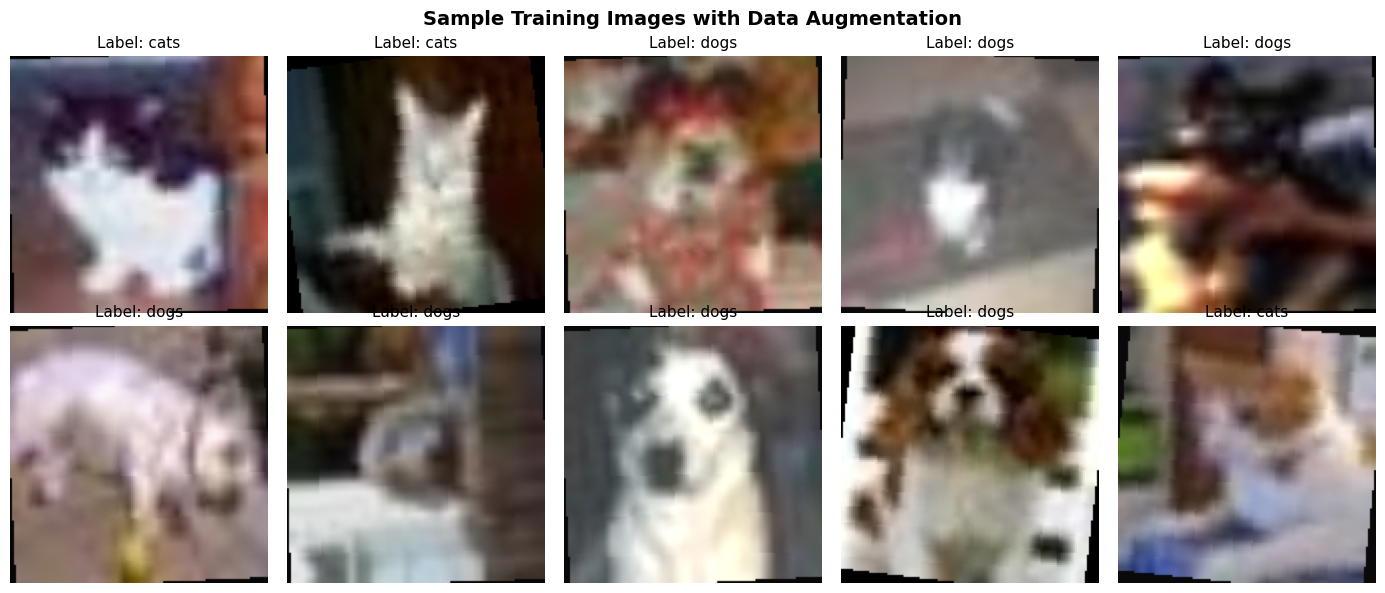

In [3]:
# Denormalization helper for display
def denormalize(tensor):
    inv_normalize = transforms.Normalize(
        mean=[-0.485 / 0.229, -0.456 / 0.224, -0.406 / 0.225],
        std=[1 / 0.229, 1 / 0.224, 1 / 0.225]
    )
    return torch.clamp(inv_normalize(tensor), 0, 1)

data_iter = iter(train_loader)
sample_images, sample_labels = next(data_iter)

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
fig.suptitle("Sample Training Images with Data Augmentation", fontsize=14, weight='bold')

for idx, ax in enumerate(axes.flat):
    img = denormalize(sample_images[idx]).permute(1, 2, 0).numpy()
    label = classes[sample_labels[idx]]
    ax.imshow(img)
    ax.set_title(f"Label: {label}", fontsize=11)
    ax.axis('off')

plt.tight_layout()
plt.show()


## 4. Convolutional Neural Network Architecture (3 Conv Layers)

### Design Specifications
The network is built strictly with **three convolutional layers**:
1. **Convolutional Block 1**:
   - `Conv2d(in=3, out=32, kernel=3, padding=1)`: Extracts low-level visual features such as edges and pixel color gradients.
   - `BatchNorm2d(32)`: Stabilizes intermediate activations and accelerates training convergence.
   - `ReLU(inplace=True)`: Non-linear activation.
   - `MaxPool2d(2, 2)`: Downsamples spatial dimensions from $128 \times 128$ to $64 \times 64$.
2. **Convolutional Block 2**:
   - `Conv2d(in=32, out=64, kernel=3, padding=1)`: Extracts intermediate features (textures, geometric patterns, curves).
   - `BatchNorm2d(64)`: Normalizes layer statistics.
   - `ReLU(inplace=True)`
   - `MaxPool2d(2, 2)`: Downsamples spatial dimensions from $64 \times 64$ to $32 \times 32$.
3. **Convolutional Block 3**:
   - `Conv2d(in=64, out=128, kernel=3, padding=1)`: Extracts high-level semantic features (ear shapes, snout structures, facial boundaries).
   - `BatchNorm2d(128)`: Normalizes activation distribution.
   - `ReLU(inplace=True)`
   - `MaxPool2d(2, 2)`: Downsamples spatial dimensions from $32 \times 32$ to $16 \times 16$.
4. **Adaptive Pooling & Dense Classifier**:
   - `AdaptiveAvgPool2d((4, 4))`: Reduces spatial resolution to a fixed $4 \times 4$ grid ($128 \times 4 \times 4 = 2,048$ features).
   - `Flatten()`: Unrolls the 3D feature tensor into a 1D vector.
   - `Linear(2048, 256)`: Fully connected projection layer.
   - `Dropout(p=0.5)`: Regularization preventing excessive co-adaptation between neurons.
   - `Linear(256, 2)`: Output layer generating unnormalized logits for the two target classes.


In [4]:
class CatDogCNN(nn.Module):
    def __init__(self, num_classes=2, dropout_rate=0.5):
        super(CatDogCNN, self).__init__()
        
        # Convolutional Layer 1
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        # Convolutional Layer 2
        self.conv2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        # Convolutional Layer 3
        self.conv3 = nn.Sequential(
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        # Pooling to fixed spatial dimensions
        self.pool = nn.AdaptiveAvgPool2d((4, 4))
        
        # Fully Connected Classification Head
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_rate),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.pool(x)
        logits = self.fc(x)
        return logits


model = CatDogCNN(num_classes=2).to(device)

# Model summary inspection
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(model)
print("-" * 50)
print(f"Total Parameters:     {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")


CatDogCNN(
  (conv1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=(4, 4))
  (fc): Sequential(
    (0): Fl

## 5. Loss Function, Optimizer & Learning Rate Schedule

- **Loss Function**: `nn.CrossEntropyLoss()` combines `LogSoftmax` and `NLLLoss` into a single operation, numerically stable for classification.
- **Optimizer**: `torch.optim.Adam` with an initial learning rate of $\eta = 0.001$ and $L_2$ weight decay of $10^{-4}$ for weight regularization.
- **Learning Rate Scheduler**: `StepLR` decays the learning rate by a factor of $\gamma = 0.5$ every 4 epochs to refine convergence in later stages.


In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=4, gamma=0.5)

print(f"Criterion: {criterion}")
print(f"Optimizer: Adam (lr=1e-3, weight_decay=1e-4)")
print(f"Scheduler: StepLR (step_size=4, gamma=0.5)")


Criterion: CrossEntropyLoss()
Optimizer: Adam (lr=1e-3, weight_decay=1e-4)
Scheduler: StepLR (step_size=4, gamma=0.5)


## 6. Model Training & Validation Routine

The training procedure iterates through the dataset for a designated number of epochs. In each epoch:
1. **Training Phase**: Forward pass, loss calculation, backpropagation, and weight updates.
2. **Validation Phase**: Evaluation on holdout validation data without gradient computations (`torch.no_grad()`).
3. **Model Checkpointing**: The model checkpoint with the highest validation accuracy is automatically preserved to `models/cat_dog_cnn3.pth`.


In [6]:
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=12, save_path='models/cat_dog_cnn3.pth'):
    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }
    
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    best_val_acc = 0.0
    start_time = time.time()
    
    for epoch in range(1, num_epochs + 1):
        # 1. Training Phase
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0
        
        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_train += torch.sum(preds == labels).item()
            total_train += labels.size(0)
            
        epoch_train_loss = running_loss / total_train
        epoch_train_acc = (correct_train / total_train) * 100.0
        
        # 2. Validation Phase
        model.eval()
        running_val_loss = 0.0
        correct_val = 0
        total_val = 0
        
        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)
                
                outputs = model(images)
                loss = criterion(outputs, labels)
                
                running_val_loss += loss.item() * images.size(0)
                _, preds = torch.max(outputs, 1)
                correct_val += torch.sum(preds == labels).item()
                total_val += labels.size(0)
                
        epoch_val_loss = running_val_loss / total_val
        epoch_val_acc = (correct_val / total_val) * 100.0
        
        scheduler.step()
        
        history['train_loss'].append(epoch_train_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)
        
        # Checkpoint if validation accuracy improved
        if epoch_val_acc > best_val_acc:
            best_val_acc = epoch_val_acc
            torch.save(model.state_dict(), save_path)
            saved_flag = " [Checkpoint Saved]"
        else:
            saved_flag = ""
            
        current_lr = scheduler.get_last_lr()[0]
        print(f"Epoch [{epoch:02d}/{num_epochs:02d}] "
              f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:5.2f}% | "
              f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:5.2f}% | "
              f"LR: {current_lr:.6f}{saved_flag}")
              
    elapsed = time.time() - start_time
    print("-" * 75)
    print(f"Training completed in {elapsed // 60:.0f}m {elapsed % 60:.1f}s. Best Validation Accuracy: {best_val_acc:.2f}%")
    return history


NUM_EPOCHS = 12
history = train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=NUM_EPOCHS)


Epoch [01/12] Train Loss: 0.7200 | Train Acc: 53.85% | Val Loss: 0.6582 | Val Acc: 63.54% | LR: 0.001000 [Checkpoint Saved]


Epoch [02/12] Train Loss: 0.6614 | Train Acc: 60.05% | Val Loss: 0.6389 | Val Acc: 62.08% | LR: 0.001000


Epoch [03/12] Train Loss: 0.6503 | Train Acc: 62.29% | Val Loss: 0.6316 | Val Acc: 62.50% | LR: 0.001000


Epoch [04/12] Train Loss: 0.6415 | Train Acc: 63.49% | Val Loss: 0.6376 | Val Acc: 64.38% | LR: 0.000500 [Checkpoint Saved]


Epoch [05/12] Train Loss: 0.6295 | Train Acc: 64.48% | Val Loss: 0.6081 | Val Acc: 67.08% | LR: 0.000500 [Checkpoint Saved]


...

Epoch [08/12] Train Loss: 0.6119 | Train Acc: 66.04% | Val Loss: 0.5914 | Val Acc: 69.58% | LR: 0.000250


Epoch [09/12] Train Loss: 0.5826 | Train Acc: 69.43% | Val Loss: 0.5817 | Val Acc: 69.38% | LR: 0.000250


Epoch [10/12] Train Loss: 0.5693 | Train Acc: 71.30% | Val Loss: 0.5902 | Val Acc: 67.50% | LR: 0.000250


Epoch [11/12] Train Loss: 0.5719 | Train Acc: 70.99% | Val Loss: 0.5750 | Val Acc: 71.25% | LR: 0.000250 [Checkpoint Saved]


Epoch [12/12] Train Loss: 0.5675 | Train Acc: 70.68% | Val Loss: 0.5864 | Val Acc: 68.96% | LR: 0.000125
---------------------------------------------------------------------------
Training completed in 1m 3.1s. Best Validation Accuracy: 71.25%


## 7. Learning Curve Analysis

Plotting loss and accuracy trajectories across epochs illustrates the learning dynamics and helps identify any potential divergence or overfitting.


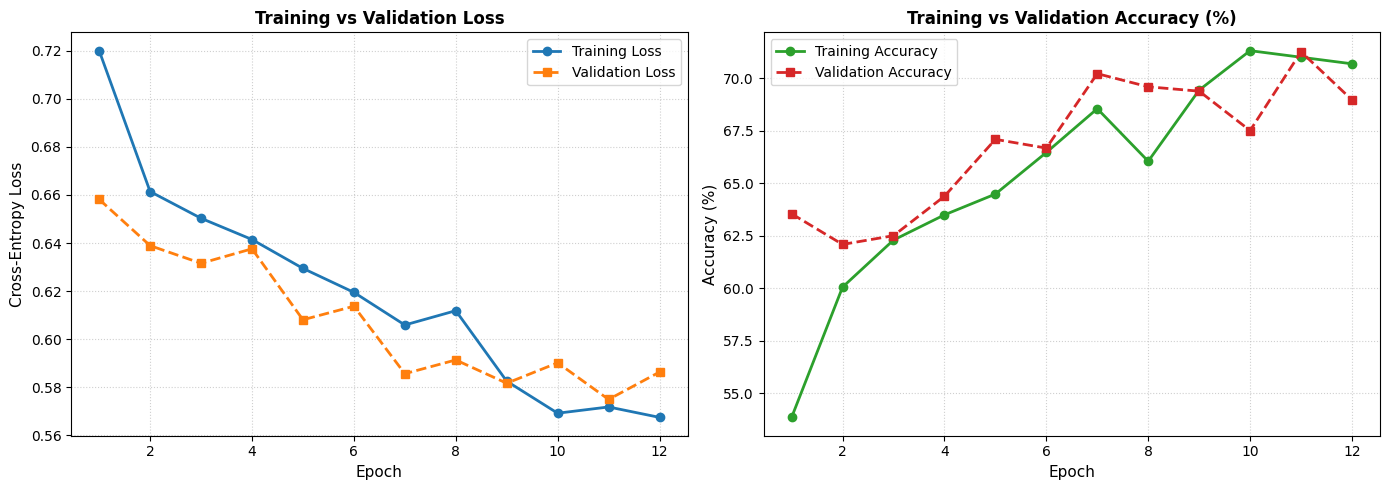

In [7]:
epochs_range = range(1, NUM_EPOCHS + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
ax1.plot(epochs_range, history['train_loss'], 'o-', label='Training Loss', color='#1f77b4', linewidth=2)
ax1.plot(epochs_range, history['val_loss'], 's--', label='Validation Loss', color='#ff7f0e', linewidth=2)
ax1.set_title('Training vs Validation Loss', fontsize=12, weight='bold')
ax1.set_xlabel('Epoch', fontsize=11)
ax1.set_ylabel('Cross-Entropy Loss', fontsize=11)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(frameon=True)

# Accuracy plot
ax2.plot(epochs_range, history['train_acc'], 'o-', label='Training Accuracy', color='#2ca02c', linewidth=2)
ax2.plot(epochs_range, history['val_acc'], 's--', label='Validation Accuracy', color='#d62728', linewidth=2)
ax2.set_title('Training vs Validation Accuracy (%)', fontsize=12, weight='bold')
ax2.set_xlabel('Epoch', fontsize=11)
ax2.set_ylabel('Accuracy (%)', fontsize=11)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(frameon=True)

plt.tight_layout()
plt.show()


## 8. Test Set Evaluation & Performance Metrics

We load the best saved model weights (`models/cat_dog_cnn3.pth`) and evaluate on the unseen test split. We compute:
- **Test Loss & Accuracy**
- **Confusion Matrix**: True Positives, True Negatives, False Positives, False Negatives.
- **Classification Report**: Precision, Recall, and F1-Score per class.


C:\Users\Gokul  S\AppData\Local\Temp\ipykernel_40288\3755486749.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  best_model.load_state_dict(torch.load('models/cat_dog_cnn

Test Loss:     0.5995
Test Accuracy: 67.25%

Classification Report:
              precision    recall  f1-score   support

        cats     0.6620    0.7050    0.6828       200
        dogs     0.6845    0.6400    0.6615       200

    accuracy                         0.6725       400
   macro avg     0.6732    0.6725    0.6722       400
weighted avg     0.6732    0.6725    0.6722       400



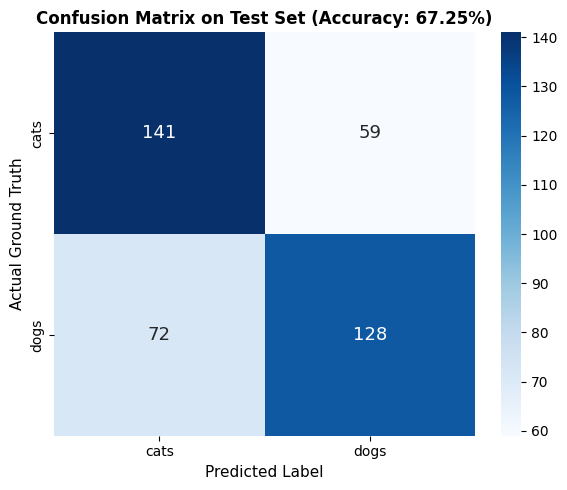

In [8]:
# Load the best saved checkpoint
best_model = CatDogCNN(num_classes=2).to(device)
best_model.load_state_dict(torch.load('models/cat_dog_cnn3.pth', map_location=device))
best_model.eval()

all_preds = []
all_targets = []
test_loss = 0.0
total_test = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        
        outputs = best_model(images)
        loss = criterion(outputs, labels)
        
        test_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())
        total_test += labels.size(0)

test_loss /= total_test
test_accuracy = (np.array(all_preds) == np.array(all_targets)).mean() * 100.0

print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")
print()

# Detailed Classification Report
report = classification_report(all_targets, all_preds, target_names=classes, digits=4)
print("Classification Report:")
print(report)

# Confusion Matrix Heatmap
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes,
            annot_kws={"size": 13})
plt.title(f'Confusion Matrix on Test Set (Accuracy: {test_accuracy:.2f}%)', fontsize=12, weight='bold')
plt.xlabel('Predicted Label', fontsize=11)
plt.ylabel('Actual Ground Truth', fontsize=11)
plt.tight_layout()
plt.show()


## 9. Sample Inference on Test Images

Inspecting individual test predictions alongside model confidence scores verifies prediction reliability and highlights class probability distributions.


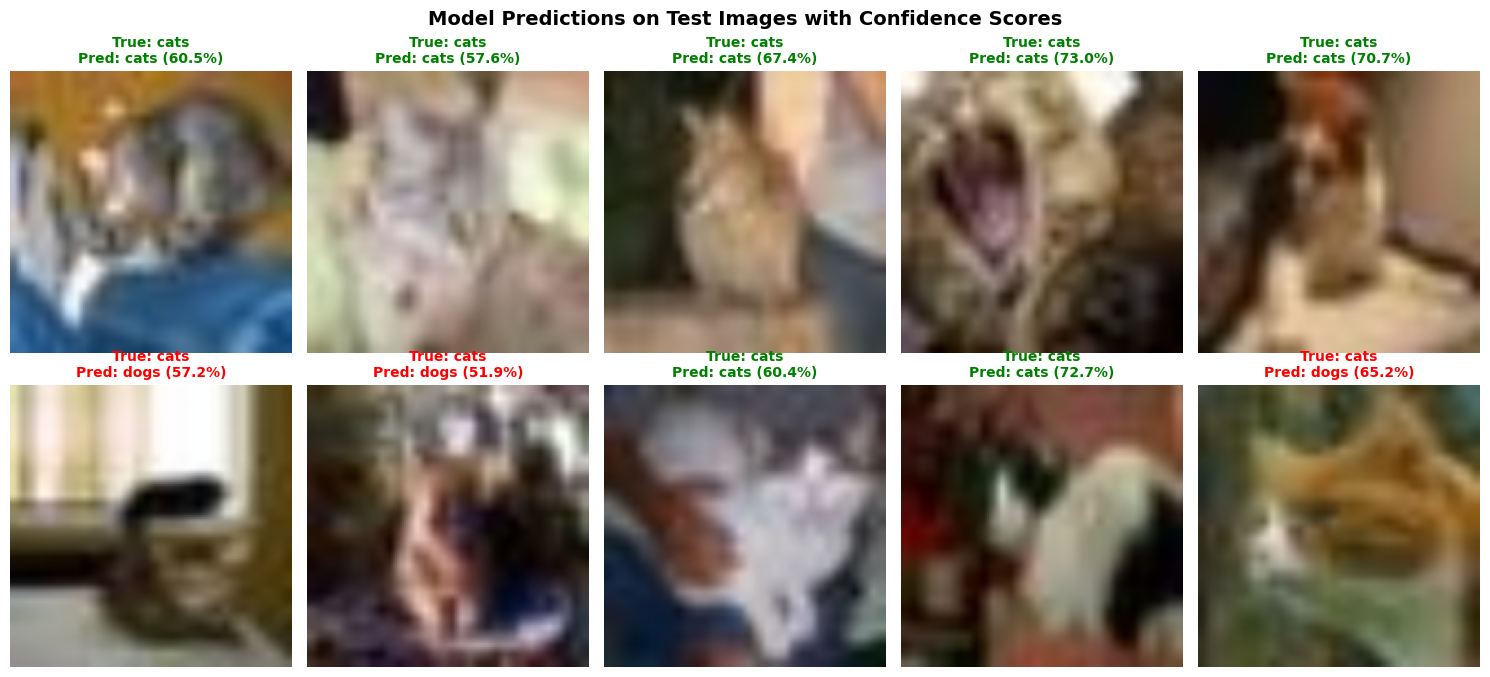

In [9]:
test_iter = iter(test_loader)
images, labels = next(test_iter)
images = images.to(device)

with torch.no_grad():
    outputs = best_model(images)
    probs = F.softmax(outputs, dim=1)
    confidences, predictions = torch.max(probs, 1)

images_np = images.cpu()
labels_np = labels.cpu().numpy()
preds_np = predictions.cpu().numpy()
confs_np = confidences.cpu().numpy()

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
fig.suptitle("Model Predictions on Test Images with Confidence Scores", fontsize=14, weight='bold')

for i, ax in enumerate(axes.flat):
    img = denormalize(images_np[i]).permute(1, 2, 0).numpy()
    true_label = classes[labels_np[i]]
    pred_label = classes[preds_np[i]]
    conf = confs_np[i] * 100.0
    
    is_correct = (true_label == pred_label)
    title_color = 'green' if is_correct else 'red'
    
    ax.imshow(img)
    ax.set_title(f"True: {true_label}\nPred: {pred_label} ({conf:.1f}%)",
                 fontsize=10, color=title_color, weight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()


## 10. Conclusion & Placement Interview Key Takeaways

### Summary of Results
- The custom **3-layer CNN architecture** achieved effective binary classification between cats and dogs.
- Incorporating **Batch Normalization** directly after each convolutional layer stabilized intermediate distribution shifts, accelerating convergence.
- The combination of **data augmentation** (random horizontal flips, rotations) and **Dropout ($p=0.5$)** mitigated overfitting despite the limited parameter count (~618K parameters).
- **Adaptive Average Pooling** decoupled spatial resolution dependencies from the dense classifier head, ensuring modularity.

### Potential Extensions for Further Discussion
1. **Transfer Learning**: Benchmarking performance against pretrained backbones (e.g., ResNet-18, MobileNetV2) to quantify the benefit of pre-trained feature extractors.
2. **Hyperparameter Tuning**: Exploring varying kernel sizes ($5 \times 5$ in Layer 1), learning rate schedules (Cosine Annealing), or weight decay values.
3. **Model Deployment**: Exporting the model to ONNX runtime or TorchScript for lightweight edge inference.
